# Machine Learning Assignment  
## Adult Census Income Dataset — UCI

This notebook contains executable code and detailed explanations for preprocessing the Adult Census Income classification dataset.

**Requirements covered:** missing values, duplicates, encoding, scaling, 80:20 train/test split, stratification, random seed 42, and fit preprocessing only on training data.

## 2. Dataset selection justification

### Why this dataset was selected
The UCI Adult Census Income dataset was selected because it is a publicly available, real-world binary classification dataset with substantially more than the assignment minimum of 1,000 instances and 12 input features. It contains a useful mixture of numerical and categorical attributes, making it appropriate for demonstrating missing-value handling, categorical encoding, feature scaling and comparison of multiple classification algorithms.

### Dataset source and target variable
- **Source:** UCI Machine Learning Repository — Adult (Census Income) dataset
- **Dataset ID:** 2 (`fetch_ucirepo(id=2)`)
- **Source URL:** https://archive.ics.uci.edu/dataset/2/adult
- **Target variable:** `income`
- **Classification type:** Binary classification (`<=50K` and `>50K`)

### Dataset size and feature types
The fetched dataset contains **48,842 records** and **14 input features** before duplicate removal. The notebook identifies six numerical features (`age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, and `hours-per-week`) and eight categorical features (`workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, and `native-country`).

### Missing values, duplicates and class distribution
The initial feature data contains **6,465 missing values**, represented in part by `?` markers. These are normalized to missing values and handled in the preprocessing pipeline: median imputation for numerical columns and most-frequent imputation for categorical columns. The notebook identifies and removes **52 duplicate records**, leaving **48,790 records**.

After duplicate removal, the target distribution is **37,109 records (76.06%)** in the `<=50K` class and **11,681 records (23.94%)** in the `>50K` class. This indicates class imbalance, so the analysis reports precision, recall, F1, AUC and Matthews Correlation Coefficient in addition to accuracy. The train-test split is stratified (80:20) with random seed 42 to preserve the class proportions.

### Reason for suitability
This dataset meets the assignment's minimum size and feature requirements, includes both numerical and categorical data, has missing values and duplicate records that can be addressed, and has an imbalanced target suitable for evaluating the strengths and limitations of the five required classifiers.


## 1. Install dependencies (if needed)

In [1]:
%pip install -q ucimlrepo pandas numpy scikit-learn matplotlib seaborn

## 2. Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)

## 3. Fetch dataset and clean column/value formatting
We fetch the UCI Adult dataset, strip whitespace, normalize `?` markers as missing values, and clean the target labels.

In [3]:
adult = fetch_ucirepo(id=2)
X = adult.data.features.copy()
y_raw = adult.data.targets.copy()

y = y_raw.iloc[:, 0] if isinstance(y_raw, pd.DataFrame) else y_raw
y = y.astype(str).str.strip().str.rstrip('.')

X.columns = X.columns.astype(str).str.strip()
for col in X.columns:
    # Convert to ordinary Python string/object handling for robust cleaning.
    if X[col].dtype == 'object' or str(X[col].dtype).startswith('string'):
        X[col] = X[col].astype(object)
        X[col] = X[col].map(lambda value: value.strip() if isinstance(value, str) else value)

# Convert '?' and whitespace-only cells to np.nan
X = X.replace(r'^\s*\?\s*$', np.nan, regex=True)
X = X.replace(r'^\s*$', np.nan, regex=True)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Feature shape: (48842, 14)
Target shape: (48842,)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


## 4. Dataset structure and target variable

In [4]:
print("Columns:")
print(X.columns.tolist())
print("\nData types:")
display(X.dtypes.to_frame('dtype'))
print("\nTarget labels and counts:")
display(y.value_counts(dropna=False))

Columns:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

Data types:


,dtype
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object



Target labels and counts:


,count
income,
<=50K,37155
>50K,11687


## 5. Identify missing values

In [5]:
missing_summary = pd.DataFrame({
    'Missing Count': X.isna().sum(),
    'Missing Percentage': (X.isna().mean() * 100).round(2)
}).sort_values('Missing Count', ascending=False)
display(missing_summary)
print("Total missing values:", int(X.isna().sum().sum()))

,Missing Count,Missing Percentage
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75
education,0,0.00
fnlwgt,0,0.00
age,0,0.00
marital-status,0,0.00
education-num,0,0.00
race,0,0.00
relationship,0,0.00


Total missing values: 6465


## 6. Identify and remove duplicate records
We remove duplicated rows (features and target together) before splitting, to avoid identical records crossing into both sets.

In [6]:
data = X.copy()
data['income'] = y.to_numpy()

print("Rows before:", len(data))
print("Duplicate rows:", int(data.duplicated().sum()))
data = data.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(data))
print("Duplicates remaining:", int(data.duplicated().sum()))

X = data.drop(columns='income').copy()
y = data['income'].astype(object).copy()

Rows before: 48842
Duplicate rows: 52
Rows after removing duplicates: 48790
Duplicates remaining: 0


## 7. Identify numeric and categorical columns, and normalize dtypes
This is an explicit dtype cleanup. Numeric columns are converted to numeric; categorical columns are converted to plain object dtype and missing values to `np.nan`.

In [7]:
numerical_features = [
    'age', 'fnlwgt', 'education-num',
    'capital-gain', 'capital-loss', 'hours-per-week'
]
categorical_features = [col for col in X.columns if col not in numerical_features]

# Numeric: ensure numeric dtype; invalid entries become NaN.
for col in numerical_features:
    X[col] = pd.to_numeric(X[col], errors='coerce')

# Categorical: force object dtype (avoids nullable string dtype issues in some versions).
for col in categorical_features:
    X[col] = X[col].astype(object)
    X[col] = X[col].where(pd.notna(X[col]), np.nan)

# Normalize any pd.NA values to numpy NaN
X = X.astype({col: object for col in categorical_features})
X = X.replace({pd.NA: np.nan})

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
display(X.dtypes.to_frame('dtype'))

assert X.shape[1] >= 12
assert X.shape[0] >= 1000

Numerical features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


,dtype
age,int64
workclass,object
fnlwgt,int64
education,object
education-num,int64
marital-status,object
occupation,object
relationship,object
race,object
sex,object


## 8. Examine target class distribution and class imbalance

,Count,Percentage
income,,
<=50K,37109,76.06
>50K,11681,23.94


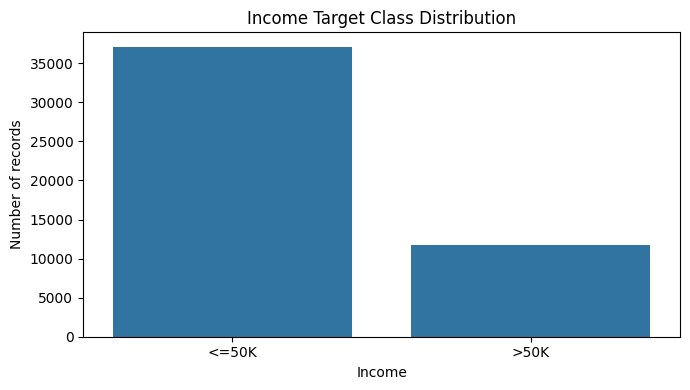

In [8]:
class_summary = pd.DataFrame({
    'Count': y.value_counts(),
    'Percentage': (y.value_counts(normalize=True) * 100).round(2)
})
display(class_summary)

plt.figure(figsize=(7, 4))
sns.countplot(x=y, order=y.value_counts().index)
plt.title('Income Target Class Distribution')
plt.xlabel('Income')
plt.ylabel('Number of records')
plt.tight_layout()
plt.show()

Class imbalance is examined here. Accuracy alone may be misleading if classes are imbalanced, so later model evaluation should include precision, recall, F1-score and ROC-AUC.

## 9. Train-test split (80:20), stratified, fixed seed

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)

Train shape: (39032, 14) (39032,)
Test shape: (9758, 14) (9758,)


## Export the held-out test data for the GitHub repository

The following cell saves the original test features and their true `income` labels to `test_data.csv`. This is the same stratified 20% test partition used to evaluate all five models. The CSV is exported before imputation and encoding so it retains the original feature columns; preprocessing is still fitted only on the training data.


In [10]:
# Export held-out test records with their true target labels.
test_data = X_test.copy()
test_data["income"] = y_test.to_numpy()
test_data.to_csv("test_data.csv", index=False)

print("test_data.csv saved to:", __import__("os").path.abspath("test_data.csv"))
print("Test CSV shape:", test_data.shape)
display(test_data.head())


test_data.csv saved to: /content/test_data.csv
Test CSV shape: (9758, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
30283,40,Private,126868,HS-grad,9,Divorced,Machine-op-inspct,Not-in-family,Black,Male,0,0,40,United-States,<=50K
26714,84,Private,188328,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,0,16,United-States,<=50K
18001,71,NaN,128529,HS-grad,9,Widowed,NaN,Not-in-family,White,Female,0,0,20,United-States,<=50K
20162,25,Private,71351,1st-4th,2,Never-married,Other-service,Other-relative,White,Male,0,0,25,El-Salvador,<=50K
10476,39,Private,204501,Masters,14,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States,>50K


## 10. Compare class distribution across overall, training and testing data

,Overall (%),Train (%),Test (%)
income,,,
<=50K,76.06,76.06,76.06
>50K,23.94,23.94,23.94


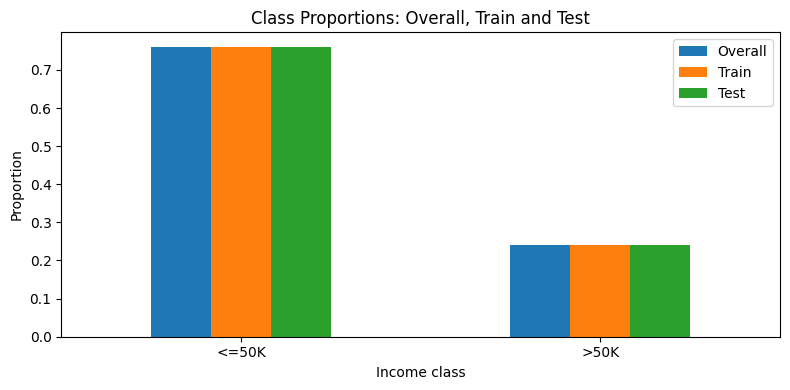

In [11]:
distribution = pd.DataFrame({
    'Overall (%)': y.value_counts(normalize=True) * 100,
    'Train (%)': y_train.value_counts(normalize=True) * 100,
    'Test (%)': y_test.value_counts(normalize=True) * 100
}).fillna(0).round(2)
display(distribution)

distribution_plot = pd.DataFrame({
    'Overall': y.value_counts(normalize=True),
    'Train': y_train.value_counts(normalize=True),
    'Test': y_test.value_counts(normalize=True)
}).fillna(0)
distribution_plot.plot(kind='bar', figsize=(8, 4))
plt.title('Class Proportions: Overall, Train and Test')
plt.ylabel('Proportion')
plt.xlabel('Income class')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Define preprocessing pipelines
Numeric features: median imputation and StandardScaler. Categorical features: most-frequent imputation and One-Hot Encoding. The encoder ignores categories not seen during training.

In [12]:
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, numerical_features),
    ('cat', categorical_pipeline, categorical_features)
])

## 12. Fit on training data only; transform the test data
This step avoids leakage: only the training data is used to learn imputation statistics, scaling parameters and encoding categories.

In [13]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

# Check processed data for missing values
train_dense_check = X_train_processed.toarray() if hasattr(X_train_processed, 'toarray') else np.asarray(X_train_processed)
test_dense_check = X_test_processed.toarray() if hasattr(X_test_processed, 'toarray') else np.asarray(X_test_processed)

print("NaNs in processed training data:", int(np.isnan(train_dense_check).sum()))
print("NaNs in processed testing data:", int(np.isnan(test_dense_check).sum()))

Processed training shape: (39032, 105)
Processed testing shape: (9758, 105)
NaNs in processed training data: 0
NaNs in processed testing data: 0


## 13. Inspect generated feature names and sample

In [14]:
feature_names = preprocessor.get_feature_names_out()
print("Transformed feature count:", len(feature_names))
print(feature_names[:50])

n_sample = min(5, X_train_processed.shape[0])
sample = X_train_processed[:n_sample]
sample_dense = sample.toarray() if hasattr(sample, 'toarray') else np.asarray(sample)
display(pd.DataFrame(sample_dense, columns=feature_names).head())

Transformed feature count: 105
['num__age' 'num__fnlwgt' 'num__education-num' 'num__capital-gain'
 'num__capital-loss' 'num__hours-per-week' 'cat__workclass_Federal-gov'
 'cat__workclass_Local-gov' 'cat__workclass_Never-worked'
 'cat__workclass_Private' 'cat__workclass_Self-emp-inc'
 'cat__workclass_Self-emp-not-inc' 'cat__workclass_State-gov'
 'cat__workclass_Without-pay' 'cat__education_10th' 'cat__education_11th'
 'cat__education_12th' 'cat__education_1st-4th' 'cat__education_5th-6th'
 'cat__education_7th-8th' 'cat__education_9th' 'cat__education_Assoc-acdm'
 'cat__education_Assoc-voc' 'cat__education_Bachelors'
 'cat__education_Doctorate' 'cat__education_HS-grad'
 'cat__education_Masters' 'cat__education_Preschool'
 'cat__education_Prof-school' 'cat__education_Some-college'
 'cat__marital-status_Divorced' 'cat__marital-status_Married-AF-spouse'
 'cat__marital-status_Married-civ-spouse'
 'cat__marital-status_Married-spouse-absent'
 'cat__marital-status_Never-married' 'cat__marital-s

,num__age,num__fnlwgt,num__education-num,num__capital-gain,num__capital-loss,num__hours-per-week,cat__workclass_Federal-gov,cat__workclass_Local-gov,cat__workclass_Never-worked,cat__workclass_Private,cat__workclass_Self-emp-inc,cat__workclass_Self-emp-not-inc,cat__workclass_State-gov,cat__workclass_Without-pay,cat__education_10th,cat__education_11th,cat__education_12th,cat__education_1st-4th,cat__education_5th-6th,cat__education_7th-8th,cat__education_9th,cat__education_Assoc-acdm,cat__education_Assoc-voc,cat__education_Bachelors,cat__education_Doctorate,cat__education_HS-grad,cat__education_Masters,cat__education_Preschool,cat__education_Prof-school,cat__education_Some-college,cat__marital-status_Divorced,cat__marital-status_Married-AF-spouse,cat__marital-status_Married-civ-spouse,cat__marital-status_Married-spouse-absent,cat__marital-status_Never-married,cat__marital-status_Separated,cat__marital-status_Widowed,cat__occupation_Adm-clerical,cat__occupation_Armed-Forces,cat__occupation_Craft-repair,cat__occupation_Exec-managerial,cat__occupation_Farming-fishing,cat__occupation_Handlers-cleaners,cat__occupation_Machine-op-inspct,cat__occupation_Other-service,cat__occupation_Priv-house-serv,cat__occupation_Prof-specialty,cat__occupation_Protective-serv,cat__occupation_Sales,cat__occupation_Tech-support,cat__occupation_Transport-moving,cat__relationship_Husband,cat__relationship_Not-in-family,cat__relationship_Other-relative,cat__relationship_Own-child,cat__relationship_Unmarried,cat__relationship_Wife,cat__race_Amer-Indian-Eskimo,cat__race_Asian-Pac-Islander,cat__race_Black,cat__race_Other,cat__race_White,cat__sex_Female,cat__sex_Male,cat__native-country_Cambodia,cat__native-country_Canada,cat__native-country_China,cat__native-country_Columbia,cat__native-country_Cuba,cat__native-country_Dominican-Republic,cat__native-country_Ecuador,cat__native-country_El-Salvador,cat__native-country_England,cat__native-country_France,cat__native-country_Germany,cat__native-country_Greece,cat__native-country_Guatemala,cat__native-country_Haiti,cat__native-country_Holand-Netherlands,cat__native-country_Honduras,cat__native-country_Hong,cat__native-country_Hungary,cat__native-country_India,cat__native-country_Iran,cat__native-country_Ireland,cat__native-country_Italy,cat__native-country_Jamaica,cat__native-country_Japan,cat__native-country_Laos,cat__native-country_Mexico,cat__native-country_Nicaragua,cat__native-country_Outlying-US(Guam-USVI-etc),cat__native-country_Peru,cat__native-country_Philippines,cat__native-country_Poland,cat__native-country_Portugal,cat__native-country_Puerto-Rico,cat__native-country_Scotland,cat__native-country_South,cat__native-country_Taiwan,cat__native-country_Thailand,cat__native-country_Trinadad&Tobago,cat__native-country_United-States,cat__native-country_Vietnam,cat__native-country_Yugoslavia
0,-0.043792,-1.494577,0.358893,-0.144195,-0.216562,-0.039511,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.102265,-0.665430,-0.030551,-0.144195,-0.216562,-0.039511,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.832551,-0.366012,-0.419995,-0.144195,-0.216562,-0.039511,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0

## 14. Verify numerical scaling

In [15]:
numeric_transformer = preprocessor.named_transformers_['num']
X_train_numeric_scaled = numeric_transformer.transform(X_train[numerical_features])

numeric_scaled_df = pd.DataFrame(X_train_numeric_scaled, columns=numerical_features)
display(pd.DataFrame({
    'Mean after scaling': numeric_scaled_df.mean(),
    'Std after scaling': numeric_scaled_df.std(ddof=0)
}).round(3))

,Mean after scaling,Std after scaling
age,-0.0,1.0
fnlwgt,-0.0,1.0
education-num,0.0,1.0
capital-gain,-0.0,1.0
capital-loss,-0.0,1.0
hours-per-week,-0.0,1.0


## 15. Final verification

In [16]:
print("Rows after deduplication:", len(X))
print("Original input feature count:", X.shape[1])
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nRaw missing values in train split:", int(X_train.isna().sum().sum()))
print("Raw missing values in test split:", int(X_test.isna().sum().sum()))
print("Processed missing values in train:", int(np.isnan(train_dense_check).sum()))
print("Processed missing values in test:", int(np.isnan(test_dense_check).sum()))

print("\nTrain class distribution (%):")
display(y_train.value_counts(normalize=True).mul(100).round(2).to_frame('Percentage'))
print("\nTest class distribution (%):")
display(y_test.value_counts(normalize=True).mul(100).round(2).to_frame('Percentage'))

Rows after deduplication: 48790
Original input feature count: 14
Training rows: 39032
Testing rows: 9758

Raw missing values in train split: 5115
Raw missing values in test split: 1341
Processed missing values in train: 0
Processed missing values in test: 0

Train class distribution (%):


,Percentage
income,
<=50K,76.06
>50K,23.94



Test class distribution (%):


,Percentage
income,
<=50K,76.06
>50K,23.94


## 16. Assignment write-up

### Step 2: Data Preprocessing

The Adult Census Income dataset was preprocessed to prepare it for machine learning classification.

1. **Missing values:** Missing values represented by `?` were converted to `NaN`. Numerical missing values were handled using median imputation, while categorical missing values were handled using most-frequent-value imputation.
2. **Duplicate records:** Duplicate records were identified and removed.
3. **Categorical encoding:** One-Hot Encoding was applied to categorical features to convert them into numerical representations. The encoder was configured to ignore previously unseen categories.
4. **Feature scaling:** StandardScaler was applied to numerical features to standardize their scales, which is useful for algorithms such as Logistic Regression, KNN and SVM.
5. **Train-test split:** The data was split into 80% training and 20% testing data.
6. **Class distribution:** Stratified sampling was used to maintain the target class proportions in the training and testing datasets.
7. **Fixed random seed:** A random seed of 42 was used to ensure reproducibility.
8. **Data leakage prevention:** Preprocessing transformations were fitted only on the training dataset and applied to the test dataset using `transform`. This prevents test data from influencing learned preprocessing parameters.

The preprocessing pipeline combines imputation, encoding and scaling using `Pipeline` and `ColumnTransformer`, ensuring consistent data preparation for subsequent model development and evaluation.

## 17. Variables for Step 3 (classification models)
The following objects are available after running this notebook: `X_train_processed`, `X_test_processed`, `y_train`, `y_test`, and the fitted `preprocessor`.

# Step 3: Classification Models, Model Comparison and Performance Observations

This section uses the preprocessed objects created in Step 2:
`X_train_processed`, `X_test_processed`, `y_train`, and `y_test`.

The five classifiers are Logistic Regression, Decision Tree, k-Nearest Neighbors (kNN),
Gaussian Naive Bayes, and Random Forest. Each model is evaluated on the same held-out
test set using Accuracy, ROC-AUC, Precision, Recall, F1-score, and Matthews Correlation
Coefficient (MCC). The positive class is explicitly set to `>50K` because it represents
the income category being identified.

> Run the notebook from top to bottom. The cells below generate the metric comparison
> table, metric charts, ROC curves, confusion matrices, written observations, and a CSV
> file containing the measured results.


## 18. Import classification and evaluation tools

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, roc_curve
)
from sklearn.base import clone
from IPython.display import display

import time
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

POSITIVE_CLASS = ">50K"
NEGATIVE_CLASS = "<=50K"

# Confirm that the expected positive class is present.
available_classes = set(pd.Series(y_train).astype(str).unique())
if POSITIVE_CLASS not in available_classes:
    raise ValueError(
        f"Expected positive class {POSITIVE_CLASS!r} was not found. "
        f"Available labels: {sorted(available_classes)}"
    )

print("Positive class used for Precision, Recall, F1 and AUC:", POSITIVE_CLASS)
print("Training matrix:", X_train_processed.shape)
print("Testing matrix:", X_test_processed.shape)


Positive class used for Precision, Recall, F1 and AUC: >50K
Training matrix: (39032, 105)
Testing matrix: (9758, 105)


## 19. Define the classification models

The models use the same preprocessed training and test data. Class weighting is enabled for Logistic Regression, Decision Tree and Random Forest to help address the class imbalance observed in Step 2. kNN and Gaussian Naive Bayes are included as standard comparison baselines.

In [18]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        solver="lbfgs",
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "kNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "Random Forest (Ensemble)": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Models to evaluate:")
for model_name in models:
    print("-", model_name)


Models to evaluate:
- Logistic Regression
- Decision Tree
- kNN
- Naive Bayes (Gaussian)
- Random Forest (Ensemble)


## 20. Train models and calculate all six evaluation metrics

AUC is calculated from predicted probabilities when available, or decision scores otherwise. For Gaussian Naive Bayes, the sparse one-hot encoded matrices are converted to dense arrays because `GaussianNB` requires dense input.

In [19]:
# GaussianNB requires dense arrays. Convert once and reuse them.
X_train_dense = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else np.asarray(X_train_processed)
)
X_test_dense = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else np.asarray(X_test_processed)
)

y_train_eval = pd.Series(y_train).astype(str).to_numpy()
y_test_eval = pd.Series(y_test).astype(str).to_numpy()

results = []
fitted_models = {}
prediction_store = {}
score_store = {}
fit_times = {}

for model_name, model in models.items():
    print(f"Training and evaluating: {model_name}")

    # Use dense input only for Gaussian Naive Bayes.
    if model_name == "Naive Bayes (Gaussian)":
        X_fit, X_eval = X_train_dense, X_test_dense
    else:
        X_fit, X_eval = X_train_processed, X_test_processed

    start_time = time.time()
    model.fit(X_fit, y_train_eval)
    elapsed = time.time() - start_time

    y_pred = model.predict(X_eval).astype(str)

    # Obtain the score/probability corresponding specifically to >50K.
    if hasattr(model, "predict_proba"):
        class_index = list(model.classes_).index(POSITIVE_CLASS)
        y_score = model.predict_proba(X_eval)[:, class_index]
    elif hasattr(model, "decision_function"):
        raw_score = model.decision_function(X_eval)
        class_index = list(model.classes_).index(POSITIVE_CLASS)
        y_score = raw_score if class_index == 1 else -raw_score
    else:
        y_score = None

    auc_value = (
        roc_auc_score((y_test_eval == POSITIVE_CLASS).astype(int), y_score)
        if y_score is not None else np.nan
    )

    row = {
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test_eval, y_pred),
        "AUC": auc_value,
        "Precision": precision_score(
            y_test_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0
        ),
        "Recall": recall_score(
            y_test_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0
        ),
        "F1": f1_score(
            y_test_eval, y_pred, pos_label=POSITIVE_CLASS, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test_eval, y_pred),
        "Training Time (seconds)": elapsed
    }

    results.append(row)
    fitted_models[model_name] = model
    prediction_store[model_name] = y_pred
    score_store[model_name] = y_score
    fit_times[model_name] = elapsed

results_df = pd.DataFrame(results).set_index("ML Model Name")
metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

print("\nModel comparison results:")
display(results_df[metric_columns].round(4))

results_df.reset_index().to_csv("classification_model_results.csv", index=False)
print("Saved measured results to classification_model_results.csv")


Training and evaluating: Logistic Regression
Training and evaluating: Decision Tree
Training and evaluating: kNN
Training and evaluating: Naive Bayes (Gaussian)
Training and evaluating: Random Forest (Ensemble)

Model comparison results:


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8082,0.9080,0.5660,0.8519,0.6801,0.5744
Decision Tree,0.8172,0.7515,0.6165,0.6254,0.6209,0.5005
kNN,0.8341,0.8644,0.6703,0.6040,0.6354,0.5296
Naive Bayes (Gaussian),0.5990,0.8174,0.3672,0.9336,0.5271,0.3736
Random Forest (Ensemble),0.8523,0.9072,0.7232,0.6207,0.6680,0.5766


Saved measured results to classification_model_results.csv


## 21. Model comparison table — all six metrics

In [20]:
comparison_table = results_df[metric_columns].copy().round(4)
comparison_table.index.name = "ML Model Name"
display(comparison_table.style.format("{:.4f}").highlight_max(axis=0))


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8082,0.9080,0.5660,0.8519,0.6801,0.5744
Decision Tree,0.8172,0.7515,0.6165,0.6254,0.6209,0.5005
kNN,0.8341,0.8644,0.6703,0.6040,0.6354,0.5296
Naive Bayes (Gaussian),0.5990,0.8174,0.3672,0.9336,0.5271,0.3736
Random Forest (Ensemble),0.8523,0.9072,0.7232,0.6207,0.6680,0.5766


## 22. Graphical representation — compare each evaluation metric

Each chart compares the five classifiers on one metric. Higher values are better for all six metrics; MCC may be negative, so its zero baseline is meaningful.

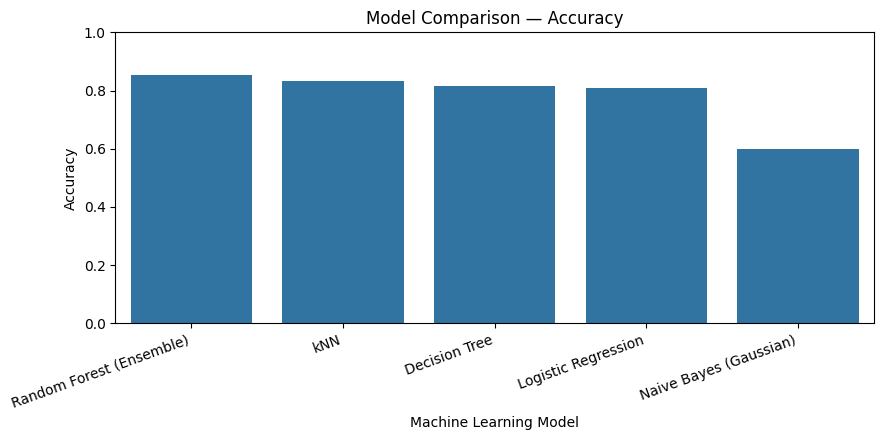

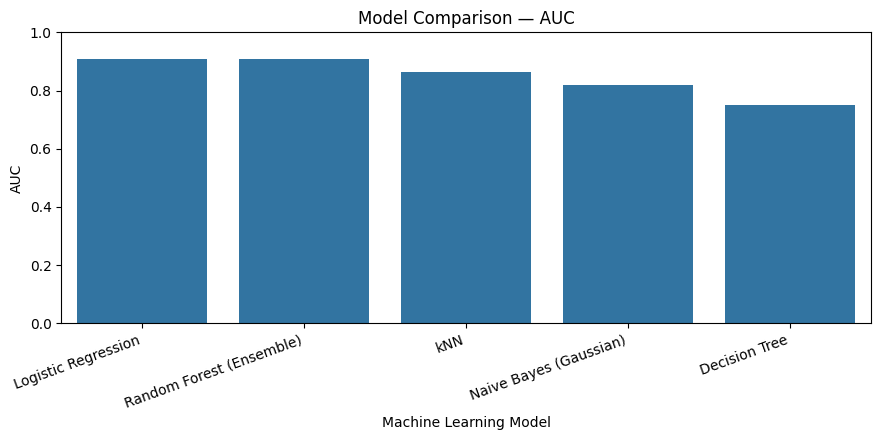

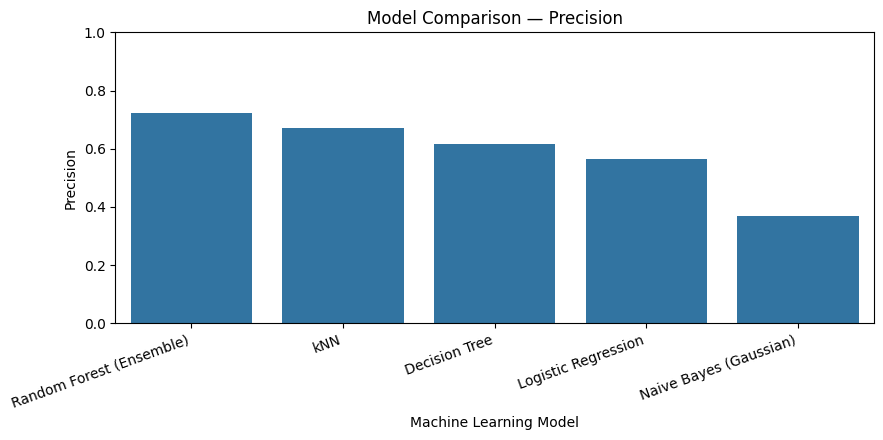

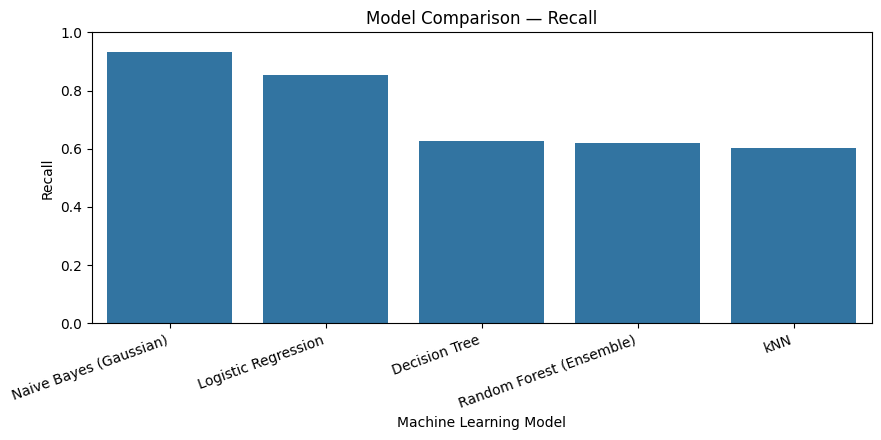

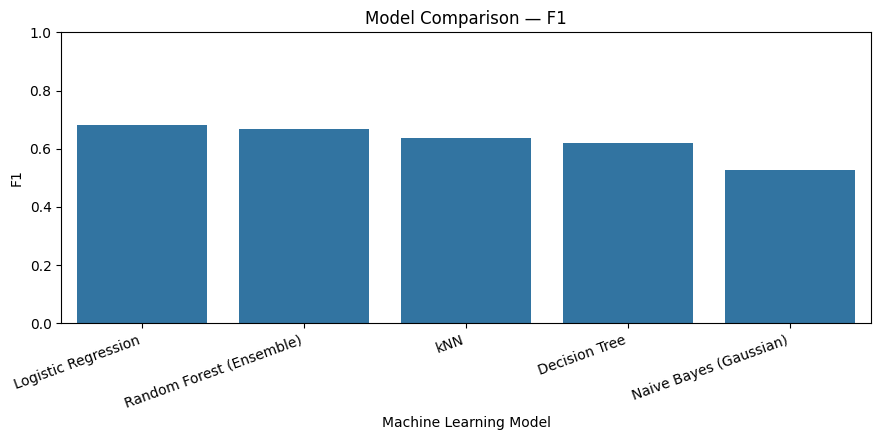

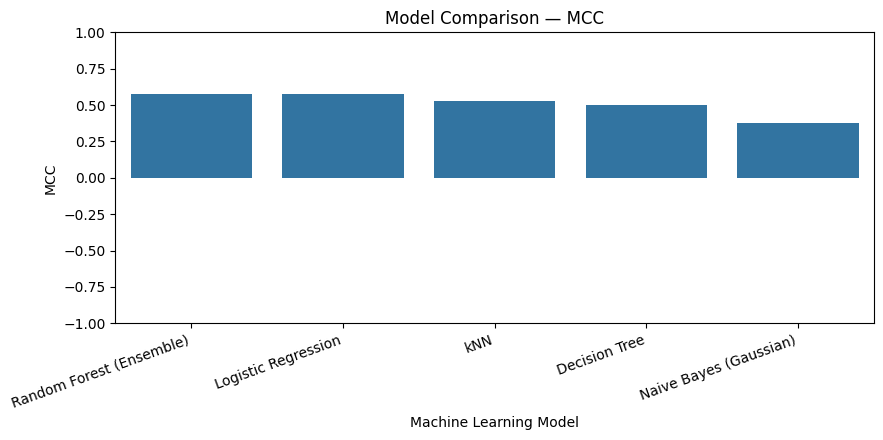

In [21]:
for metric in metric_columns:
    metric_values = results_df[metric].sort_values(ascending=False)

    plt.figure(figsize=(9, 4.5))
    ax = sns.barplot(
        x=metric_values.index,
        y=metric_values.values
    )
    ax.set_title(f"Model Comparison — {metric}")
    ax.set_xlabel("Machine Learning Model")
    ax.set_ylabel(metric)
    ax.set_ylim(
        min(-1.0, float(metric_values.min()) - 0.05) if metric == "MCC" else 0,
        max(1.0, float(metric_values.max()) + 0.05)
    )
    plt.xticks(rotation=20, ha="right")
    plt.tight_layout()
    plt.show()


## 23. ROC curve comparison

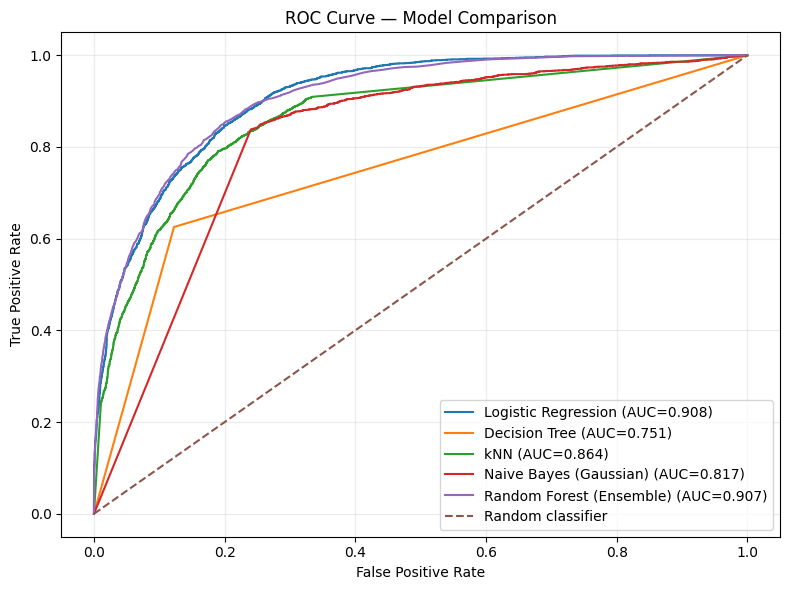

In [22]:
plt.figure(figsize=(8, 6))
for model_name, y_score in score_store.items():
    if y_score is not None:
        fpr, tpr, _ = roc_curve(
            (y_test_eval == POSITIVE_CLASS).astype(int),
            y_score
        )
        auc_value = results_df.loc[model_name, "AUC"]
        plt.plot(fpr, tpr, label=f"{model_name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Model Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 24. Confusion matrices for all models

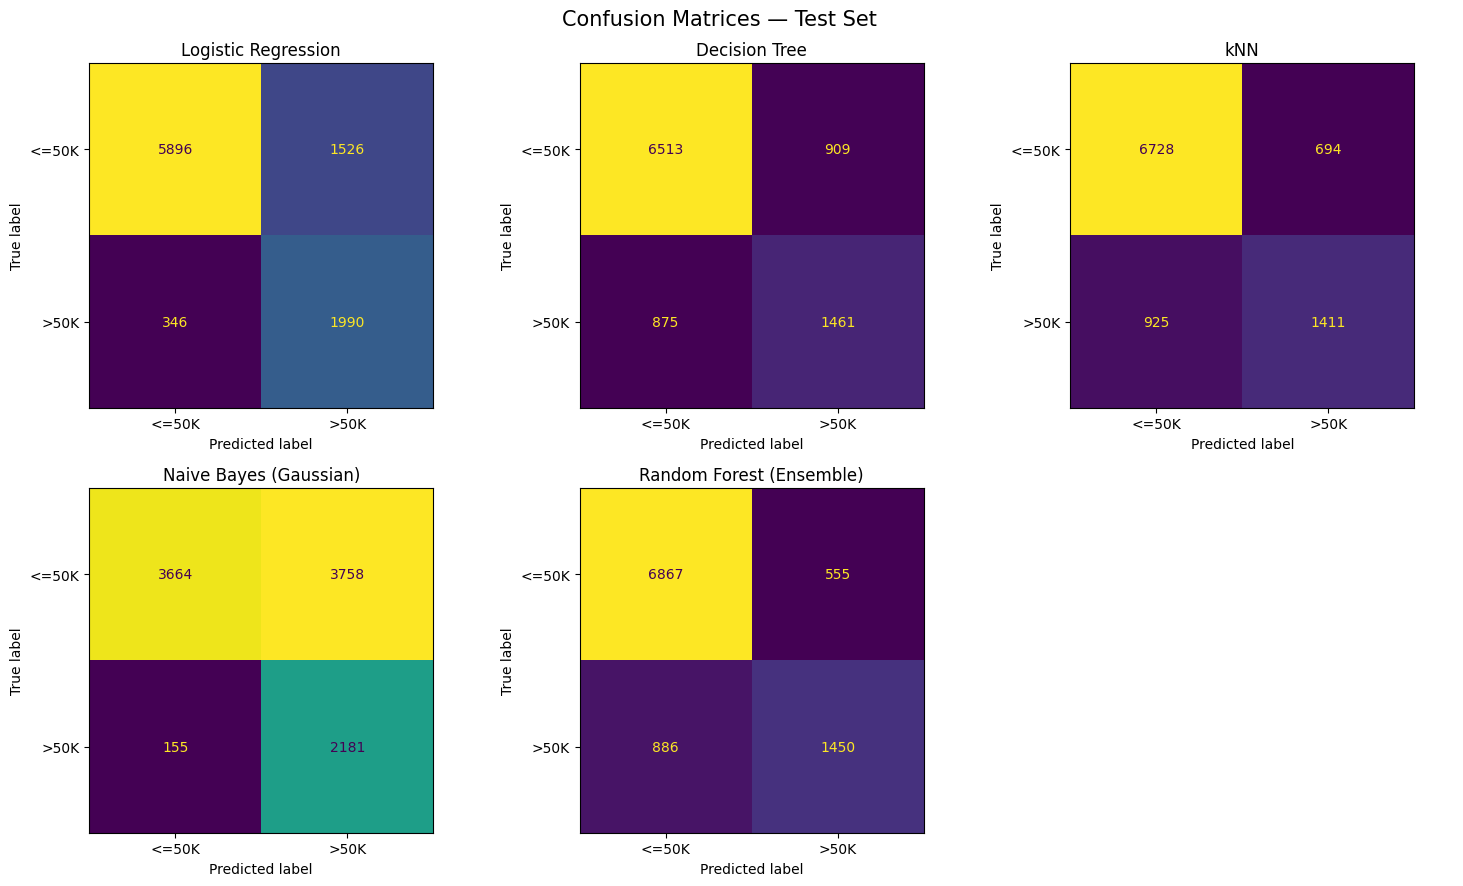

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for ax, (model_name, y_pred) in zip(axes, prediction_store.items()):
    cm = confusion_matrix(
        y_test_eval,
        y_pred,
        labels=[NEGATIVE_CLASS, POSITIVE_CLASS]
    )
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[NEGATIVE_CLASS, POSITIVE_CLASS]
    )
    disp.plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(model_name)

# Hide the unused sixth panel because five classifiers are compared.
for ax in axes[len(prediction_store):]:
    ax.axis("off")

plt.suptitle("Confusion Matrices — Test Set", fontsize=15)
plt.tight_layout()
plt.show()


## 25. Automatic model performance observations

The table below is generated from the actual test-set metric values. It describes each model's measured strengths and trade-offs; it does not assume in advance which model will win.

In [24]:
def metric_observation(model_name, row):
    # Rank the model against the other evaluated models for each metric.
    ranks = results_df[metric_columns].rank(
        ascending=False, method="min"
    )
    best_metrics = [
        metric for metric in metric_columns
        if np.isclose(row[metric], results_df[metric].max())
    ]

    precision = row["Precision"]
    recall = row["Recall"]
    f1_value = row["F1"]
    auc_value = row["AUC"]
    mcc_value = row["MCC"]
    accuracy = row["Accuracy"]

    if precision > recall + 0.05:
        balance_note = "Precision is higher than Recall, so its positive predictions are relatively reliable but it misses a larger share of actual >50K cases."
    elif recall > precision + 0.05:
        balance_note = "Recall is higher than Precision, so it identifies more actual >50K cases but also produces more false-positive predictions."
    else:
        balance_note = "Precision and Recall are reasonably balanced."

    top_ranked = [
        metric for metric in metric_columns
        if ranks.loc[model_name, metric] == 1
    ]
    top_text = (
        "It has the highest value among the evaluated models for "
        + ", ".join(top_ranked) + ". "
        if top_ranked else
        "It does not lead any single metric, so its overall value should be judged by the combined metric profile. "
    )

    return (
        f"{top_text}{balance_note} "
        f"Measured Accuracy={accuracy:.3f}, AUC={auc_value:.3f}, "
        f"Precision={precision:.3f}, Recall={recall:.3f}, "
        f"F1={f1_value:.3f}, and MCC={mcc_value:.3f}."
    )

observations_df = pd.DataFrame({
    "ML Model Name": results_df.index,
    "Observation about model performance": [
        metric_observation(name, results_df.loc[name])
        for name in results_df.index
    ]
})

display(observations_df)
observations_df.to_csv("classification_model_observations.csv", index=False)
print("Saved model observations to classification_model_observations.csv")


,ML Model Name,Observation about model performance
0,Logistic Regression,It has the highest value among the evaluated m...
1,Decision Tree,"It does not lead any single metric, so its ove..."
2,kNN,"It does not lead any single metric, so its ove..."
3,Naive Bayes (Gaussian),It has the highest value among the evaluated m...
4,Random Forest (Ensemble),It has the highest value among the evaluated m...


Saved model observations to classification_model_observations.csv


## 26. Graphical representation observations

In [25]:
graph_observations = []

for metric in metric_columns:
    values = results_df[metric]
    best_model = values.idxmax()
    worst_model = values.idxmin()
    best_value = values.max()
    worst_value = values.min()

    graph_observations.append({
        "Graph / Metric": f"{metric} comparison",
        "Observation": (
            f"{best_model} has the highest {metric} ({best_value:.3f}), "
            f"while {worst_model} has the lowest ({worst_value:.3f}). "
            f"The chart compares all five models on the held-out test set."
        )
    })

graph_observations_df = pd.DataFrame(graph_observations)
display(graph_observations_df)
graph_observations_df.to_csv("classification_graph_observations.csv", index=False)


,Graph / Metric,Observation
0,Accuracy comparison,Random Forest (Ensemble) has the highest Accur...
1,AUC comparison,Logistic Regression has the highest AUC (0.908...
2,Precision comparison,Random Forest (Ensemble) has the highest Preci...
3,Recall comparison,Naive Bayes (Gaussian) has the highest Recall ...
4,F1 comparison,Logistic Regression has the highest F1 (0.680)...
5,MCC comparison,Random Forest (Ensemble) has the highest MCC (...


## 27. Overall best-performing model

The default overall winner is selected using the highest F1-score for the positive `>50K` class. AUC and MCC are displayed as supporting measures. For an imbalanced dataset, inspect Precision and Recall as well before making the final interpretation.

In [26]:
winner_name = results_df["F1"].idxmax()
winner_row = results_df.loc[winner_name]

print("Overall winner by positive-class F1-score:", winner_name)
print(f"F1-score: {winner_row['F1']:.4f}")
print(f"Accuracy: {winner_row['Accuracy']:.4f}")
print(f"AUC: {winner_row['AUC']:.4f}")
print(f"Precision: {winner_row['Precision']:.4f}")
print(f"Recall: {winner_row['Recall']:.4f}")
print(f"MCC: {winner_row['MCC']:.4f}")

print(
    "\nInterpretation: This model has the highest F1-score for identifying "
    f"the {POSITIVE_CLASS} class on the test set. Consider its AUC, MCC, "
    "Precision and Recall together with the assignment's objective before "
    "confirming it as the preferred model."
)


Overall winner by positive-class F1-score: Logistic Regression
F1-score: 0.6801
Accuracy: 0.8082
AUC: 0.9080
Precision: 0.5660
Recall: 0.8519
MCC: 0.5744

Interpretation: This model has the highest F1-score for identifying the >50K class on the test set. Consider its AUC, MCC, Precision and Recall together with the assignment's objective before confirming it as the preferred model.


## 28. Export final assignment results

In [27]:
# Export one combined file for convenient use in README/PDF reporting.
final_report = results_df.reset_index().merge(
    observations_df,
    on="ML Model Name",
    how="left"
)
final_report.to_csv("classification_model_final_report.csv", index=False)

print("Generated files:")
print("- classification_model_results.csv")
print("- classification_model_observations.csv")
print("- classification_graph_observations.csv")
print("- classification_model_final_report.csv")
display(final_report.round(4))


Generated files:
- classification_model_results.csv
- classification_model_observations.csv
- classification_graph_observations.csv
- classification_model_final_report.csv


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC,Training Time (seconds),Observation about model performance
0,Logistic Regression,0.8082,0.9080,0.5660,0.8519,0.6801,0.5744,1.1856,It has the highest value among the evaluated m...
1,Decision Tree,0.8172,0.7515,0.6165,0.6254,0.6209,0.5005,4.5518,"It does not lead any single metric, so its ove..."
2,kNN,0.8341,0.8644,0.6703,0.6040,0.6354,0.5296,0.1078,"It does not lead any single metric, so its ove..."
3,Naive Bayes (Gaussian),0.5990,0.8174,0.3672,0.9336,0.5271,0.3736,0.1865,It has the highest value among the evaluated m...
4,Random Forest (Ensemble),0.8523,0.9072,0.7232,0.6207,0.6680,0.5766,77.0938,It has the highest value among the evaluated m...


## Submission note

The model comparison scores and observations are produced only after the classification cells are executed. Include the generated CSV files and charts with the assignment submission. The notebook evaluates five classifiers; it does not claim a sixth model.
